# How much of an ARAM Mayhem game is decided at champion select?

ARAM Mayhem hands every player a random champion, so the draft is close to a coin someone else flips for you.
This notebook asks how well the final 5v5 draft predicts the winner, using a baseline, logistic regression and
gradient boosting, all scored out-of-fold with repeated cross-validation, a permutation test, calibration and a
later-patch holdout.

**Short answer** (774 games, patches 26.3 to 26.22):

* **The draft matters, but only a little.** The best model, one feature summing each champion's patch-wide win
  rate, ranks winners with an out-of-fold AUC of **0.60** (95% CI 0.56 to 0.64) and gets **58%** of games right,
  against 55% for always picking blue. A permutation test puts the chance of this by luck at about 1 in 300.
* **Patch-wide win rates carry over almost one-to-one.** Rates measured on a much larger player base in another
  region predict these games with a slope of about 0.8 (CI includes 1).
* **Blue side wins 55%** of these games (95% CI 51.5% to 58.5%).
* **More detail didn't help yet.** Team-composition features (class mix, damage type, tankiness) and per-champion
  ratings scored *worse* than the single prior: with ~170 champions and 774 games, every extra parameter costs
  more in noise than it adds in signal. Learning curves show the one-feature model is already saturated while the
  per-champion model is still climbing, so the next gain comes from more games, not a fancier model.
* **The model is honest about its uncertainty.** Its probabilities stay between about 40% and 70%, and the
  calibration plot follows the diagonal within the intervals.

How to rerun: build the private game table with `games.py` (see the README), then
`WINMODEL_GAMES=path/to/games.json jupyter nbconvert --execute --to notebook --inplace win_prediction.ipynb`.

In [1]:
import json, os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

sys.path.insert(0, os.path.abspath("."))
import games as G
import winmodel as W

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

PATH = os.environ.get("WINMODEL_GAMES", G.DEFAULT_OUT)
games = json.load(open(PATH))
traits = W.Traits()
feats, onehot, champs, y = W.design(games, traits)
print(f"{len(games)} games, {len(champs)} different champions, "
      f"{games[0]['date'][:7]} to {games[-1]['date'][:7]}")

774 games, 173 different champions, 2026-02 to 2026-11


## 1. The data

Every game is ARAM Mayhem (queue 2400) from one player's synced match history. Each row keeps only the draft
(five champions a side), the patch, the date, the game length and the result. Games under five minutes
(remakes) are dropped.
No names, account ids or per-player stats are kept, and the table itself is not in the repository: only the
aggregate numbers below are.

Two things to keep in mind:
* **One player is in every game.** That player's skill sits on one team in every row and the model can't see
  which, so it adds noise rather than bias to a draft-only model. Results describe this player's games, not all
  of Mayhem.
* **Augments are left out.** They are picked during the game, so they aren't draft information.
* **Matchmaking assigns champions at random** (ARAM rerolls aside), so the draft is close to a natural
  experiment: what each side gets isn't chosen to counter the other side.

In [2]:
df = pd.DataFrame({"patch": [W.official_patch(g["patch"]) for g in games],
                   "blue_win": y, "minutes": [g["duration"] / 60 for g in games]})
per_patch = (df.groupby("patch", sort=False).agg(games=("blue_win", "size"), blue_win_rate=("blue_win", "mean"))
             .reset_index())
per_patch["key"] = per_patch["patch"].map(lambda p: tuple(map(int, p.split("."))))
per_patch = per_patch.sort_values("key").drop(columns="key")
k, n = int(y.sum()), len(y)
lo, hi = W.wilson(k, n)
test = binomtest(k, n, 0.5)
print(f"Blue side won {k}/{n} = {k/n:.1%} (95% CI {lo:.1%} to {hi:.1%}, two-sided p = {test.pvalue:.3f})")
print(f"Median game length {df.minutes.median():.1f} min")
per_patch.set_index("patch").T

Blue side won 426/774 = 55.0% (95% CI 51.5% to 58.5%, two-sided p = 0.006)
Median game length 17.7 min


patch,26.3,26.4,26.5,26.12,26.13,26.14,26.15,26.16,26.17,26.18,26.19,26.21,26.22
games,29.000,27.000,7.000,40.00,145.0,153.00,127.000,30.000,65.000,29.000,14.000,92.000,16.0
blue_win_rate,0.621,0.593,0.429,0.45,0.6,0.51,0.559,0.567,0.569,0.552,0.714,0.511,0.5


## 2. Features

Everything is **blue minus red**, so positive always favours blue and the intercept is the side advantage.

| Feature set | What it is | Columns |
|---|---|---|
| **Side only** (baseline) | Predict the training set's blue win rate for every game | 0 |
| **Draft prior** | Sum of each champion's server-wide win rate on that patch, as log-odds | 1 |
| **Team composition** | Draft prior + team damage share, tank share, ranged count, magic-damage count, damage mix, a frontline flag and class counts | 13 |
| **Champion identity** | +1 for each blue champion, -1 for each red one (a Bradley-Terry style rating per champion) | ~170 |

The draft prior, damage share and tank share come from patch-level stats over a far larger player base, not
from these games, so they leak nothing about the results being predicted. Champion class, range and damage type
come from Data Dragon.

## 3. Models and validation

* Logistic regression with an L2 penalty picked by an inner 5-fold CV on log loss (nested inside the outer CV).
* Gradient boosting kept small on purpose (depth-2 trees, 150 rounds, 40-game leaves) so it can't memorise 1,000
  games.
* Every score is **out-of-fold**: 5-fold stratified CV repeated 10 times. The table shows the mean over repeats
  and a bootstrap 95% interval over games.
* Metrics: **AUC** (ranking: 0.5 is a coin flip), **accuracy**, **log loss** and **Brier score** (both reward
  honest probabilities; lower is better). Accuracy alone is misleading here because blue wins more than half.

In [3]:
X_prior = W.matrix(feats, W.DRAFT_FEATURES)
X_comp = W.matrix(feats, W.COMP_FEATURES)
X_champ = onehot
X_champ_prior = np.column_stack([X_prior, onehot])

candidates = {
    "Side only (baseline)": (W.SideRate(), X_prior),
    "Draft prior, logistic": (W.logistic(), X_prior),
    "Team composition, logistic": (W.logistic(), X_comp),
    "Team composition, gradient boosting": (W.boosting(), X_comp),
    "Champion identity, logistic": (W.logistic(), X_champ),
    "Champion identity + draft prior, logistic": (W.logistic(), X_champ_prior),
}
oof, rows = {}, []
for name, (model, X) in candidates.items():
    oof[name] = W.out_of_fold(model, X, y, repeats=10)
    mean, ci = W.summarise(y, oof[name])
    rows.append({"model": name, **{m: mean[m] for m in mean},
                 "AUC 95% CI": f"{ci['auc'][0]:.3f} to {ci['auc'][1]:.3f}"})
results = pd.DataFrame(rows).set_index("model")
results

,auc,accuracy,log_loss,brier,AUC 95% CI
model,,,,,
Side only (baseline),0.497,0.550,0.688,0.247,0.445 to 0.526
"Draft prior, logistic",0.598,0.584,0.674,0.240,0.558 to 0.637
"Team composition, logistic",0.562,0.578,0.683,0.245,0.524 to 0.606
"Team composition, gradient boosting",0.565,0.562,0.694,0.249,0.530 to 0.612
"Champion identity, logistic",0.521,0.548,0.688,0.247,0.483 to 0.564
"Champion identity + draft prior, logistic",0.542,0.555,0.685,0.246,0.504 to 0.584


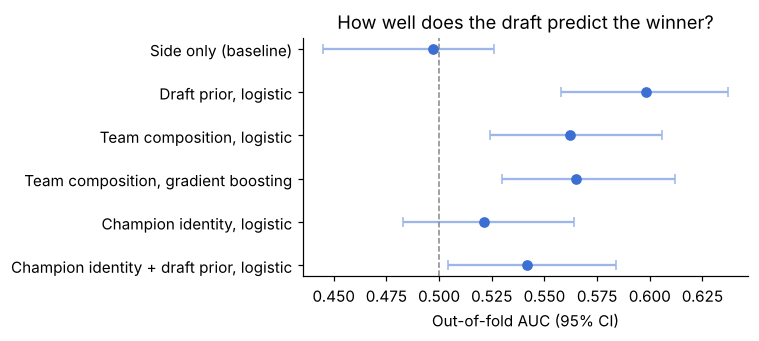

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
order = results.index[::-1]
aucs = results.loc[order, "auc"]
cis = [tuple(map(float, s.split(" to "))) for s in results.loc[order, "AUC 95% CI"]]
ax.errorbar(aucs, range(len(order)), xerr=[[a - c[0] for a, c in zip(aucs, cis)], [c[1] - a for a, c in zip(aucs, cis)]],
            fmt="o", color="#3b6fd4", ecolor="#9db6ea", capsize=3)
ax.axvline(0.5, color="#888", ls="--", lw=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Out-of-fold AUC (95% CI)")
ax.set_title("How well does the draft predict the winner?")
plt.tight_layout()

## 4. Is the signal real?

A permutation test: shuffle the results, retrain the draft-prior model (one feature, so no penalty search), and repeat 300 times. The p-value is how
often a model trained on shuffled results ranks games as well as the real one.

Permutation p-value: 0.0033


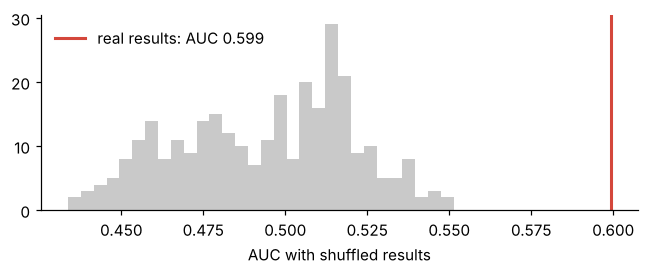

In [5]:
real, null, p = W.permutation_auc(W.logistic(cv_c=False), X_prior, y, n=300)
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(null, bins=30, color="#c9c9c9")
ax.axvline(real, color="#d4473b", lw=2, label=f"real results: AUC {real:.3f}")
ax.set_xlabel("AUC with shuffled results")
ax.legend(frameon=False)
plt.tight_layout()
print(f"Permutation p-value: {p:.4f}")

### Do patch-wide win rates carry over to these games?

The draft prior is built from win rates measured on a different, much larger set of players (another region's
server). If those numbers transfer one-to-one, an unpenalised logistic regression on the prior should have a
slope of 1. A slope near 0 would mean they say nothing about these games; above 1 would mean they understate
the gaps.

In [6]:
slope = W.prior_slope(X_prior[:, 0], y, boot=1000)
print(f"Slope {slope['slope']:.2f} (95% CI {slope['slope_ci'][0]:.2f} to {slope['slope_ci'][1]:.2f})")
print(f"Blue side intercept {slope['intercept']:+.2f} log-odds = {slope['side_pp']:+.1f} percentage points "
      f"at an even draft (95% CI {slope['side_pp_ci'][0]:+.1f} to {slope['side_pp_ci'][1]:+.1f})")
print(f"A one-SD draft edge ({slope['sd']:.2f} log-odds of summed prior) moves the win chance by "
      f"{slope['one_sd_pp']:.1f} percentage points")

Slope 0.83 (95% CI 0.52 to 1.17)
Blue side intercept +0.19 log-odds = +4.7 percentage points at an even draft (95% CI +1.0 to +8.2)
A one-SD draft edge (0.46 log-odds of summed prior) moves the win chance by 9.2 percentage points


## 5. Calibration

When the model says blue has a 60% chance, does blue win about 60% of those games? Games are split into eight
equal-size groups by predicted probability; bars are Wilson 95% intervals on the observed win rate.

,n,predicted,observed,lo,hi
0,97,0.411,0.361,0.272,0.460
1,97,0.476,0.495,0.397,0.593
2,97,0.512,0.454,0.358,0.553
3,97,0.541,0.577,0.478,0.671
4,97,0.568,0.639,0.540,0.728
5,97,0.595,0.639,0.540,0.728
6,96,0.623,0.604,0.504,0.696
7,96,0.680,0.635,0.536,0.725


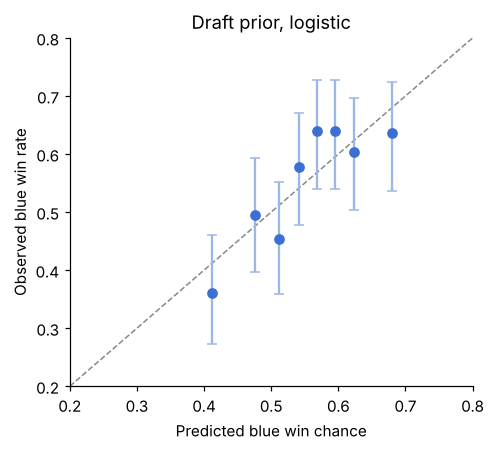

In [7]:
best = "Draft prior, logistic"
p_best = oof[best].mean(axis=0)
rel = pd.DataFrame(W.reliability(y, p_best, bins=8))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0.2, 0.8], [0.2, 0.8], color="#888", ls="--", lw=1)
ax.errorbar(rel.predicted, rel.observed, yerr=[rel.observed - rel.lo, rel.hi - rel.observed], fmt="o",
            color="#3b6fd4", ecolor="#9db6ea", capsize=3)
ax.set_xlabel("Predicted blue win chance"); ax.set_ylabel("Observed blue win rate")
ax.set_title(best); ax.set_xlim(0.2, 0.8); ax.set_ylim(0.2, 0.8)
plt.tight_layout()
rel

## 6. What in a composition matters?

Standardised logistic coefficients for the team-composition model (one standard deviation of each blue-minus-red
feature), with bootstrap 95% intervals. Intervals that cross zero are indistinguishable from no effect at this
sample size. The features are correlated (tanks have high tank share, mages deal magic damage), so read these as
"given the others", not as standalone effects.

L2 penalty chosen by CV: C = 0.01


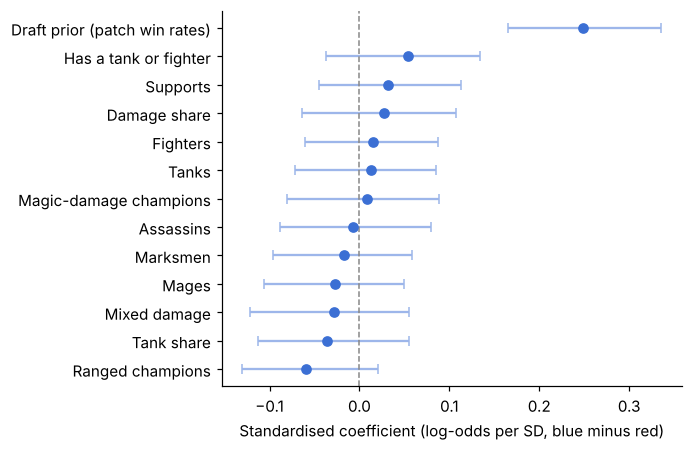

In [8]:
coefs, C = W.bootstrap_coefs(X_comp, y, W.COMP_FEATURES, boot=500)
labels = {"prior": "Draft prior (patch win rates)", "dmg": "Damage share", "tank": "Tank share",
          "ranged": "Ranged champions", "magic": "Magic-damage champions", "damage_mix": "Mixed damage",
          "has_frontline": "Has a tank or fighter"}
cf = pd.DataFrame(coefs)
plural = {"Marksman": "Marksmen"}
cf["feature"] = cf["feature"].map(lambda f: labels.get(f, plural.get(f, f + "s")))
cf = cf.sort_values("coef")
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.errorbar(cf.coef, range(len(cf)), xerr=[cf.coef - cf.lo, cf.hi - cf.coef], fmt="o", color="#3b6fd4",
            ecolor="#9db6ea", capsize=3)
ax.axvline(0, color="#888", ls="--", lw=1)
ax.set_yticks(range(len(cf)), cf.feature)
ax.set_xlabel("Standardised coefficient (log-odds per SD, blue minus red)")
plt.tight_layout()
print(f"L2 penalty chosen by CV: C = {C:g}")

## 7. How much data would a better model need?

Learning curves: train on *n* games, score on held-out games, 20 random draws per size. If a curve is still
rising at the right edge, more games will help; if it is flat, the features are the limit.

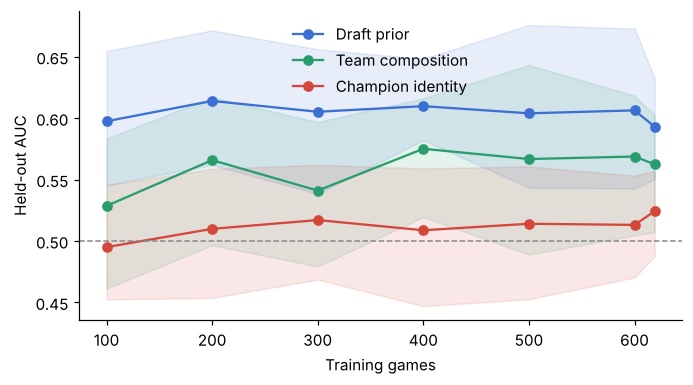

In [9]:
sizes = [100, 200, 300, 400, 500, 600, 700, int(len(y) * 0.8)]
sizes = sorted({s for s in sizes if s <= int(len(y) * 0.8)})
curves = {
    "Draft prior": W.learning_curve(W.logistic(), X_prior, y, sizes, repeats=20),
    "Team composition": W.learning_curve(W.logistic(), X_comp, y, sizes, repeats=20),
    "Champion identity": W.learning_curve(W.logistic(), X_champ, y, sizes, repeats=20),
}
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for (name, c), col in zip(curves.items(), ["#3b6fd4", "#2a9d6f", "#d4473b"]):
    c = pd.DataFrame(c)
    ax.plot(c.n, c.auc, "o-", color=col, label=name)
    ax.fill_between(c.n, c.p10, c.p90, color=col, alpha=0.12)
ax.axhline(0.5, color="#888", ls="--", lw=1)
ax.set_xlabel("Training games"); ax.set_ylabel("Held-out AUC")
ax.legend(frameon=False)
plt.tight_layout()

## 8. Does it hold up on later patches?

Random CV mixes old and new patches. A stricter test trains only on games before October 2026 and scores the
games played after it, the way the model would be used.

In [10]:
dates = np.array([g["date"] for g in games])
train, test = dates < "2026-10-01", dates >= "2026-10-01"
rows = []
for name, (model, X) in candidates.items():
    m = W.SideRate() if isinstance(model, W.SideRate) else W.clone(model)
    m.fit(X[train], y[train])
    rows.append({"model": name, **W.scores(y[test], m.predict_proba(X[test])[:, 1])})
print(f"train {train.sum()} games (before October 2026), test {test.sum()} games (October 2026 on)")
pd.DataFrame(rows).set_index("model")

train 660 games (before October 2026), test 114 games (October 2026 on)


,auc,accuracy,log_loss,brier
model,,,,
Side only (baseline),0.500,0.526,0.693,0.250
"Draft prior, logistic",0.643,0.579,0.668,0.238
"Team composition, logistic",0.578,0.570,0.682,0.244
"Team composition, gradient boosting",0.635,0.588,0.658,0.234
"Champion identity, logistic",0.568,0.535,0.689,0.248
"Champion identity + draft prior, logistic",0.588,0.535,0.685,0.246


## 9. When is the draft decisive?

How often the draft-prior model's favourite wins, split by how confident it is.

In [11]:
fav = np.maximum(p_best, 1 - p_best)
right = (p_best > 0.5) == (y == 1)
bands = pd.cut(fav, [0.5, 0.55, 0.6, 0.65, 1.0], labels=["50-55%", "55-60%", "60-65%", "65%+"], include_lowest=True)
conf = pd.DataFrame({"band": bands, "right": right}).groupby("band", observed=False).agg(
    games=("right", "size"), favourite_won=("right", "mean"))
conf["share_of_games"] = conf.games / conf.games.sum()
conf

,games,favourite_won,share_of_games
band,,,
50-55%,287,0.512,0.371
55-60%,243,0.613,0.314
60-65%,163,0.656,0.211
65%+,81,0.617,0.105


## 10. Takeaways and limits

**What the numbers say.** In these games the draft is worth a few percentage points, not a verdict. For the 37% of
games the model rates as near-even (50-55%), its favourite wins 51% of the time: a coin flip. When one side's draft
is clearly stronger (60%+, a third of games), the favourite wins about 64% of the time. That fits the mode's design:
random champions, short games and frequent teamfights leave a lot to execution, and to augments picked
mid-game.

**Why the simple model wins.** A single, externally estimated number per champion beats ~170 champion ratings
learned from 774 games because each champion appears only about 45 times here, while the patch-wide rates come
from a sample several orders of magnitude larger. This is the bias-variance trade-off in its plainest form:
borrow strength from a big, slightly mismatched sample instead of fitting a small, perfectly matched one.

**Limits.**
* One player appears in every game, and the model can't see which side they are on. The results describe this
  player's games, not the whole player base.
* 774 games is small for a 5v5 problem. Interval widths in every table reflect that; overlapping intervals mean
  "can't tell apart", not "the same".
* The later-patch holdout has only 114 games, so its scores swing more than the cross-validated ones.
* Augments, items, levels and player skill are left out on purpose: the question is what the draft alone tells
  you.

**Next steps.**
1. Rerun on the full history (older games add about 40% more data) and on the opt-in shared-games pool as it
   grows; the learning curves say per-champion effects need thousands of games.
2. Hierarchical model: shrink each champion's rating toward its patch-wide prior instead of toward zero, which
   keeps the strong prior and lets the data adjust it.
3. Pairwise synergy terms (champion x champion on the same team) once the sample supports them.
4. A post-draft model with augments, framed separately because augments are chosen in-game.